In [1]:
import pandas as pd
import geopandas as gpd

from pathlib import Path

In [2]:
src_dir = Path('~').expanduser() / 'data/ivs/iww-route-assignment'

In [3]:
telpunt_gdf = gpd.read_file(src_dir / 'euris_with_telpunt.gpkg')
ivs_df = pd.read_csv(src_dir / 'IVS_Reizenbestand_2026_volgorde.csv', delimiter=';')
ivs_df

/var/folders/1z/6xp0rndx2nqc7qx263rv42fh0000gn/T/ipykernel_39179/421414026.py:2: DtypeWarning: Columns (0: Pseudo_ReisID) have mixed types. Specify dtype option on import or set low_memory=False.
  ivs_df = pd.read_csv(src_dir / 'IVS_Reizenbestand_2026_volgorde.csv', delimiter=';')


,Pseudo_ReisID,v05_06_Begindt_evenement,IOL_TRAJECT_CD
0,NaN,01Jan2026:00:03:00,G20B7
1,NaN,01Jan2026:00:11:00,G20SW
2,NaN,01Jan2026:00:17:00,G20HK
3,NaN,01Jan2026:00:17:00,G20SW
4,NaN,01Jan2026:00:19:00,G20H2
...,...,...,...
4138594,9999943f54dc152bd65,30Jul2026:13:06:00,Z01HD
4138595,9999943f54dc152bd65,30Jul2026:14:08:00,Z01HD
4138596,9999943f54dc152bd65,30Jul2026:14:27:00,G10HD
4138597,9999943f54dc152bd65,30Jul2026:15:53:00,G14BN


In [4]:
ivs_merged_df = ivs_df.merge(telpunt_gdf, left_on='IOL_TRAJECT_CD', right_on='OBJECT ID')
ivs_merged_gdf = gpd.GeoDataFrame(ivs_merged_df, geometry='geometry')

In [5]:
pd.read_parquet("/Users/hemert/projects/iww-route-assignment-sito-is/fis-crawler/output/ivs-assignment/trips_with_paths.parquet")

,unlo_herkomst,unlo_bestemming,sk_code,nstr_nw,trips,cargo_weight_kg,nodes
0,ATKRE,NLAMS,C3l,1,1,1106462.0,"[EURIS_AT_J0002, EURIS_AT_J0074, EURIS_AT_J004..."
1,ATKRE,NLAMS,M6,1,1,301000.0,"[EURIS_AT_J0002, EURIS_AT_J0074, EURIS_AT_J004..."
2,ATKRE,NLAMS,M7,1,1,400000.0,"[EURIS_AT_J0002, EURIS_AT_J0074, EURIS_AT_J004..."
3,ATKRE,NLAMS,M7,6,1,216000.0,"[EURIS_AT_J0002, EURIS_AT_J0074, EURIS_AT_J004..."
4,ATLNZ,BEANR,C3l,5,1,2410000.0,"[EURIS_AT_J0055, EURIS_AT_J0027, EURIS_AT_J005..."
...,...,...,...,...,...,...,...
23098,SKBAB,BEANR,M5,9,1,150000.0,"[EURIS_SK_J0012, EURIS_SK_J0021, EURIS_SK_J002..."
23099,SKBAB,BEANR,M8,9,1,381000.0,"[EURIS_SK_J0012, EURIS_SK_J0021, EURIS_SK_J002..."
23100,SKBAB,NLMST,M8,2,1,500000.0,"[EURIS_SK_J0012, EURIS_SK_J0021, EURIS_SK_J002..."
23101,SKBAB,NLRTM,M8,9,1,730000.0,"[EURIS_SK_J0012, EURIS_SK_J0021, EURIS_SK_J002..."


In [6]:
ivs_merged_gdf.to_file(src_dir / 'ivs_route_with_edge_geometry.gpkg')

In [7]:
ivs_merged_gdf.to_parquet(src_dir / 'ivs_route_with_edge_geometry.parquet')

<Axes: >

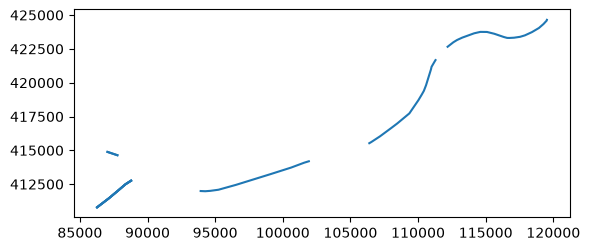

In [8]:
ivs_merged_gdf[ivs_merged_gdf['Pseudo_ReisID'] == '9999943f54dc152bd65'].plot()

In [11]:
ivs_merged_gdf

,Pseudo_ReisID,v05_06_Begindt_evenement,IOL_TRAJECT_CD,OBJECT ID,Id,type,vaarweg,hectometer,isrsCode,naam,...,length_m,borderpoint,locode,speed_maxspeed,speed_calspeed,speed_direction,speed_shipcategory,distance_join,point_wkt,geometry
0,NaN,01Jan2026:00:03:00,G20B7,G20B7,11500016,BRUG,115,16,NLRTM0115B5487800010,HARTELBRUG,...,1674.333302,None,None,NaN,NaN,NaN,NaN,0.968848,POINT (80640.462966 431359.171353),"LINESTRING (81603 431392, 80606 431359, 79931 ..."
1,NaN,01Jan2026:00:11:00,G20SW,G20SW,10210066,BLOK,102,10066,NaN,STAD WEST ROTTERDAM,...,381.126617,None,None,NaN,NaN,NaN,NaN,15.611640,POINT (88963.676441 435287.925801),"LINESTRING (89312 435277.001, 88932 435306)"
2,NaN,01Jan2026:00:17:00,G20HK,G20HK,11500117,BLOK,115,117,NaN,HARTELKANAAL,...,7017.047204,None,None,NaN,NaN,NaN,NaN,0.010221,POINT (72515.34652 436691.452645),"LINESTRING (74951 434515.001, 74796 434799, 74..."
3,NaN,01Jan2026:00:17:00,G20SW,G20SW,10210066,BLOK,102,10066,NaN,STAD WEST ROTTERDAM,...,381.126617,None,None,NaN,NaN,NaN,NaN,15.611640,POINT (88963.676441 435287.925801),"LINESTRING (89312 435277.001, 88932 435306)"
4,NaN,01Jan2026:00:19:00,G20H2,G20H2,11600004,BLOK,116,4,NaN,HARTELKANAAL 2,...,5245.316018,None,None,NaN,NaN,NaN,NaN,0.043712,POINT (77543.017203 431424.041009),"LINESTRING (79931 431407.001, 79731 431421, 79..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4124936,9999943f54dc152bd65,30Jul2026:13:06:00,Z01HD,Z01HD,11209975,BLOK,112,9975,NaN,HOLLANDSCH DIEP,...,3347.711326,None,None,NaN,NaN,NaN,NaN,0.009054,POINT (88522.456869 412589.523863),"LINESTRING (88849 412799, 88369.655 412491.518..."
4124937,9999943f54dc152bd65,30Jul2026:14:08:00,Z01HD,Z01HD,11209975,BLOK,112,9975,NaN,HOLLANDSCH DIEP,...,3347.711326,None,None,NaN,NaN,NaN,NaN,0.009054,POINT (88522.456869 412589.523863),"LINESTRING (88849 412799, 88369.655 412491.518..."
4124938,9999943f54dc152bd65,30Jul2026:14:27:00,G10HD,G10HD,11209891,BLOK,112,9891,NaN,HOLLANDSCH DIEP,...,8483.930988,None,None,NaN,NaN,NaN,NaN,0.050523,POINT (97093.677429 412620.854828),"LINESTRING (101999.766 414215.144, 101578 4140..."
4124939,9999943f54dc152bd65,30Jul2026:15:53:00,G14BN,G14BN,10800001,BLOK,108,1,NaN,BLOK NIEUWE MERWEDE,...,8277.762948,None,None,NaN,NaN,NaN,NaN,0.006107,POINT (109563.742297 418033.692832),"LINESTRING (111331.758 421737.972, 111242.635 ..."
